# Word legibility pipeline (IMGUR5K)

Builds a large legibility training set from IMGUR5K handwritten words, labeled the same way as the signatures: TrOCR reads each cleaned image and the reading is compared with the known word (Levenshtein similarity, letters only).

**Run the cells top to bottom.** The first block of cells only defines functions. The **Steps** section at the bottom does the work, one step per cell, and each step can be rerun on its own.

Leakage rules built in: IMGUR5K's own train/val/test files decide the split, each word keeps its photo id as its group, duplicate photos are removed (train copy kept), and the threshold is chosen before anything is scored on the signature holdout.

Needs: `numpy pandas pillow scipy`; `torch transformers` for the OCR step; `rapidfuzz` optional.

## Functions (run these cells, nothing happens yet)

In [1]:
import argparse
import hashlib
import json
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage

SIZE = 256
SPLITS = ("train", "val", "test")

In [2]:
# Cleaning: one function for words, signatures and Tobacco800
def clean_gray(g):
    """uint8 grayscale (dark ink on light paper) -> uint8, ink dark on white.
    1. flatten uneven lighting: divide by a background estimate (grey closing
       removes the thin ink strokes and keeps the paper/lighting);
    2. stretch contrast: black point = 1st percentile (ink), white point =
       90th percentile (paper; most pixels in a word or signature crop are
       paper), so leftover paper texture is pushed to pure white."""
    g = g.astype(np.float32)
    k = int(max(15, min(g.shape) // 2)) | 1
    bg = ndimage.grey_closing(g, size=(k, k))
    flat = np.clip(g / np.maximum(bg, 1.0), 0, 1) * 255.0
    lo, hi = np.percentile(flat, 1), np.percentile(flat, 90)
    if hi - lo < 20:                       # blank or nearly blank: leave white
        return np.full(g.shape, 255, np.uint8)
    out = np.clip((flat - lo) / (hi - lo), 0, 1) * 255.0
    return out.astype(np.uint8)


def to_square(g, size=SIZE, margin=0.08):
    """Pad onto a white square (like the signature images) and resize."""
    h, w = g.shape
    side = int(max(h, w) * (1 + 2 * margin))
    canvas = np.full((side, side), 255, np.uint8)
    y0, x0 = (side - h) // 2, (side - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = g
    return np.asarray(Image.fromarray(canvas).resize((size, size), Image.LANCZOS))


def crop_rotated(img, xc, yc, w, h, angle, angle_sign=1.0, pad=0.10):
    """Cut a rotated box out of a PIL grayscale image and return it upright."""
    w2, h2 = w * (1 + pad), h * (1 + pad)
    r = int(np.ceil(np.hypot(w2, h2) / 2)) + 2
    x0, y0 = int(xc - r), int(yc - r)
    region = Image.new("L", (2 * r, 2 * r), 255)          # white outside the photo
    inside = img.crop((max(x0, 0), max(y0, 0), min(x0 + 2 * r, img.width), min(y0 + 2 * r, img.height)))
    region.paste(inside, (max(x0, 0) - x0, max(y0, 0) - y0))
    region = region.rotate(angle_sign * angle, resample=Image.BICUBIC, fillcolor=255)
    c = region.size[0] / 2
    box = (int(c - w2 / 2), int(c - h2 / 2), int(c + w2 / 2), int(c + h2 / 2))
    return np.asarray(region.crop(box))


def dhash(img, n=32):
    """Difference hash on a 32x33 thumbnail: compares neighbouring pixels, so it
    tracks the writing rather than the overall lighting. Survives re-uploads
    and resizing of the same photo; different photos almost never collide."""
    small = np.asarray(img.convert("L").resize((n + 1, n), Image.BOX), dtype=np.float32)
    bits = (small[:, 1:] > small[:, :-1]).ravel()
    return "".join("1" if v else "0" for v in bits)

In [3]:
# Text normalisation and similarity (letters only, lower case)
def letters(s):
    return re.sub("[^a-z]", "", str(s).lower()) if pd.notna(s) else ""


try:
    from rapidfuzz.distance import Levenshtein as _lev

    def lev(a, b):
        return _lev.distance(a, b)
except ImportError:
    def lev(a, b):
        if len(a) < len(b):
            a, b = b, a
        prev = list(range(len(b) + 1))
        for i, ca in enumerate(a, 1):
            cur = [i]
            for j, cb in enumerate(b, 1):
                cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
            prev = cur
        return prev[-1]


def similarity(read, target):
    a, b = letters(read), letters(target)
    if not b:
        return np.nan
    return 1.0 - lev(a, b) / max(len(a), len(b))

In [4]:
# Step: prepare
def load_split(info_dir, split):
    p = Path(info_dir) / f"imgur5k_annotations_{split}.json"
    d = json.loads(p.read_text())
    need = {"index_id", "index_to_ann_map", "ann_id"}
    if not need <= set(d):
        sys.exit(f"{p.name}: expected keys {sorted(need)}, found {sorted(d)}")
    return d


def find_image(image_dir, image_id, info):
    cand = []
    if isinstance(info, dict) and info.get("image_path"):
        cand.append(Path(info["image_path"]))
        cand.append(Path(image_dir) / Path(info["image_path"]).name)
    cand += sorted(Path(image_dir).glob(f"{image_id}.*"))
    return next((c for c in cand if c.exists()), None)


def cmd_prepare(a):
    out = Path(a.out)
    out.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(a.seed)
    quota = {"train": a.max_train, "val": a.max_val, "test": a.max_test}

    # 1. candidate words per split, with filters
    rows, missing = [], 0
    for split in SPLITS:
        d = load_split(a.info_dir, split)
        for image_id, ann_ids in d["index_to_ann_map"].items():
            path = find_image(a.image_dir, image_id, d["index_id"].get(image_id, {}))
            if path is None:
                missing += 1
                continue
            for ann in ann_ids:
                rec = d["ann_id"].get(ann, {})
                word = str(rec.get("word", "")).strip()
                core = word.strip(".,;:!?\"'()[]")
                if word == "." or not re.fullmatch(r"[A-Za-z]+", core) or len(core) < a.min_letters:
                    continue
                try:
                    xc, yc, w, h, ang = [float(v) for v in json.loads(rec["bounding_box"])]
                except (KeyError, ValueError, TypeError):
                    continue
                if w < a.min_w or h < a.min_h:
                    continue
                rows.append(dict(split=split, image_id=image_id, ann_id=ann, word=core,
                                 xc=xc, yc=yc, w=w, h=h, angle=ang, path=str(path)))
    cand = pd.DataFrame(rows)
    print(f"Candidate words after filters: {len(cand)} "
          f"({cand.groupby('split').size().to_dict()}); images not downloaded: {missing}")

    # 2. de-duplicate photos (exact bytes and near-identical look)
    imgs = cand.drop_duplicates("image_id")[["image_id", "split", "path"]].copy()
    md5, ah = [], []
    for p in imgs["path"]:
        md5.append(hashlib.md5(Path(p).read_bytes()).hexdigest())
        try:
            with Image.open(p) as im:
                ah.append(dhash(im))
        except Exception:
            ah.append(None)
    imgs["md5"], imgs["ahash"] = md5, ah
    imgs = imgs[imgs["ahash"].notna()]
    order = {"train": 0, "val": 1, "test": 2}
    imgs = imgs.sort_values("split", key=lambda s: s.map(order)).reset_index(drop=True)  # train first
    # near-duplicates: Hamming distance between hashes below a.dup_frac of the bits
    B = np.array([[c == "1" for c in h] for h in imgs["ahash"]], dtype=np.float32)
    ham = B @ (1 - B).T + (1 - B) @ B.T
    near = ham <= a.dup_frac * B.shape[1]
    keep = ~imgs.duplicated("md5").to_numpy()
    for i in range(len(imgs)):                      # keep the first copy (train before val/test)
        if keep[i] and near[i, :i][keep[:i]].any():
            keep[i] = False
    print(f"Duplicate photos removed: {int((~keep).sum())}")
    cand = cand[cand["image_id"].isin(imgs.loc[keep, "image_id"])]

    # 3. random subsample per split (whole words; image_id kept as the group)
    parts = []
    for split, sub in cand.groupby("split"):
        n = min(len(sub), quota[split])
        parts.append(sub.iloc[rng.permutation(len(sub))[:n]])
    sel = pd.concat(parts).sort_values(["split", "image_id"]).reset_index(drop=True)

    # 4. crop, clean, square, write to a memory-mapped .npy
    arr = np.lib.format.open_memmap(out / "words_256.npy", mode="w+",
                                    dtype=np.uint8, shape=(len(sel), SIZE, SIZE))
    ok = np.ones(len(sel), bool)
    t0, cur_path, cur_img = time.time(), None, None
    for i, r in sel.iterrows():
        if r.path != cur_path:
            with Image.open(r.path) as im:
                cur_img = im.convert("L")
            cur_path = r.path
        try:
            crop = crop_rotated(cur_img, r.xc, r.yc, r.w, r.h, r.angle, a.angle_sign)
            arr[i] = to_square(clean_gray(crop))
        except Exception:
            ok[i] = False
            arr[i] = 255
        if i and i % 5000 == 0:
            print(f"  {i}/{len(sel)} crops ({time.time() - t0:.0f}s)")
    arr.flush()
    sel["ok"] = ok
    sel["idx"] = np.arange(len(sel))
    sel["group"] = sel["image_id"]
    sel.drop(columns=["path"]).to_csv(out / "words_meta.csv", index=False)
    print(f"Wrote {out/'words_256.npy'} {arr.shape} and words_meta.csv; "
          f"failed crops: {int((~ok).sum())}")
    print(sel.groupby("split").agg(words=("idx", "size"), photos=("image_id", "nunique")))

In [5]:
# Step: preview (look before you OCR)
def cmd_preview(a):
    arr = np.load(a.images, mmap_mode="r")
    meta = pd.read_csv(a.meta)
    rng = np.random.default_rng(0)
    idx = rng.choice(len(arr), size=min(a.n, len(arr)), replace=False)
    cols, cell = 8, 128
    rows = int(np.ceil(len(idx) / cols))
    sheet = Image.new("L", (cols * cell, rows * (cell + 14)), 255)
    from PIL import ImageDraw
    draw = ImageDraw.Draw(sheet)
    col = a.text_col if a.text_col in meta.columns else None
    for k, i in enumerate(idx):
        x, y = (k % cols) * cell, (k // cols) * (cell + 14)
        sheet.paste(Image.fromarray(np.asarray(arr[i])).resize((cell, cell)), (x, y))
        if col:
            draw.text((x + 2, y + cell), str(meta[col].iloc[i])[:20], fill=0)
    sheet.save(a.out)
    print(f"Saved {a.out}")

In [6]:
# Step: ocr (batched, fp16, checkpointed, resumable)
class OCRDataset:
    """Module level so DataLoader workers can pickle it (needed on Windows).
    Cleaning and resizing run here, on CPU workers; the GPU only runs TrOCR."""

    def __init__(self, path, todo, proc):
        self.path, self.todo, self.proc, self.arr = path, todo, proc, None

    def __len__(self):
        return len(self.todo)

    def __getitem__(self, k):
        if self.arr is None:                               # open once per worker
            self.arr = np.load(self.path, mmap_mode="r")
        i = self.todo[k]
        g = clean_gray(np.asarray(self.arr[i]))   # same step for words and signatures
        px = self.proc(images=Image.fromarray(g).convert("RGB"), return_tensors="pt").pixel_values[0]
        return i, px


def cmd_ocr(a):
    import torch
    from transformers import TrOCRProcessor, VisionEncoderDecoderModel

    arr = np.load(a.images, mmap_mode="r")
    meta = pd.read_csv(a.meta)
    if len(meta) != len(arr):
        sys.exit(f"meta has {len(meta)} rows, images has {len(arr)}")
    if a.text_col not in meta.columns:
        sys.exit(f"column '{a.text_col}' not in {a.meta}")
    out = Path(a.out)
    done = set(pd.read_csv(out)["idx"]) if out.exists() else set()
    todo = [i for i in range(len(arr)) if i not in done
            and ("ok" not in meta.columns or bool(meta["ok"].iloc[i]))]
    if a.limit:
        todo = todo[:a.limit]
    print(f"{len(done)} already done, {len(todo)} to read")
    if not todo:
        return

    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dtype = torch.float16 if dev.type == "cuda" and not a.fp32 else torch.float32
    proc = TrOCRProcessor.from_pretrained(a.model)
    model = VisionEncoderDecoderModel.from_pretrained(a.model, torch_dtype=dtype).to(dev).eval()

    ds = OCRDataset(a.images, todo, proc)
    dl = torch.utils.data.DataLoader(ds, batch_size=a.batch_size, num_workers=a.workers,
                                     pin_memory=dev.type == "cuda")
    buf, t0, n = [], time.time(), 0
    header = not out.exists()
    with torch.inference_mode():
        for ids, px in dl:
            gen = model.generate(px.to(dev, dtype=dtype, non_blocking=True),
                                 num_beams=1, max_new_tokens=a.max_new_tokens)
            texts = proc.batch_decode(gen, skip_special_tokens=True)
            for i, t in zip(ids.tolist(), texts):
                buf.append({"idx": i, "target": meta[a.text_col].iloc[i], "ocr": t})
            n += len(texts)
            if len(buf) >= a.flush_every:
                pd.DataFrame(buf).to_csv(out, mode="a", header=header, index=False)
                header, buf = False, []
                rate = n / (time.time() - t0)
                print(f"  {n}/{len(todo)} read, {rate:.1f} img/s, "
                      f"~{(len(todo) - n) / rate / 60:.0f} min left")
    if buf:
        pd.DataFrame(buf).to_csv(out, mode="a", header=header, index=False)
    print(f"Done: {out} ({model.config._name_or_path}, {dtype}, greedy, "
          f"max_new_tokens={a.max_new_tokens})")

In [7]:
# Step: label
def cmd_label(a):
    o = pd.read_csv(a.ocr).drop_duplicates("idx").sort_values("idx")
    o["similarity"] = [similarity(r, t) for r, t in zip(o["ocr"], o["target"])]
    o["label"] = (o["similarity"] >= a.threshold).astype(int)
    if a.meta:
        m = pd.read_csv(a.meta)
        keep = [c for c in ("split", "group", "word", "source_family", "label") if c in m.columns]
        m = m[keep].rename(columns={"label": "old_label"})
        o = o.merge(m, left_on="idx", right_index=True, how="left")
    o.to_csv(a.out, index=False)
    print(f"Saved {a.out}: {len(o)} rows, threshold {a.threshold}")
    print("Legible rate at other thresholds (decide BEFORE looking at the holdout):")
    for t in (0.6, 0.7, 0.8, 0.9, 1.0):
        print(f"  >= {t:.1f}: {(o['similarity'] >= t).mean():.3f}")
    if "split" in o.columns:
        print(o.groupby("split")["label"].agg(["size", "mean"]).rename(columns={"mean": "legible"}))
    if "old_label" in o.columns:
        agree = (o["label"] == o["old_label"]).mean()
        print(f"Agreement with the earlier labels: {agree:.3f}")

## Steps

All paths are relative to this notebook's folder (Run Program).

### Step 1: download IMGUR5K (once)
Downloads the official IMGUR5K code and runs its download script, which fetches the photos from Imgur. Some links are dead; that is expected. This can take a while.

In [8]:
# Fixes "CERTIFICATE_VERIFY_FAILED" on Windows: use Windows' own certificate store
# (truststore) and give the download script a certificate bundle (certifi).
# First time only, install them:   %pip install truststore certifi requests
import os, ssl, subprocess, sys, urllib.request, zipfile, io
from pathlib import Path
import certifi

try:
    import truststore
    truststore.inject_into_ssl()                 # this notebook trusts what Windows trusts
except ImportError:
    print("truststore not installed; using certifi only")
os.environ["SSL_CERT_FILE"] = certifi.where()    # for the download script below
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

REPO = Path("IMGUR5K-Handwriting-Dataset")
if not REPO.exists():
    for branch in ("main", "master"):
        try:
            url = f"https://github.com/facebookresearch/IMGUR5K-Handwriting-Dataset/archive/refs/heads/{branch}.zip"
            zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(".")
            Path(f"IMGUR5K-Handwriting-Dataset-{branch}").rename(REPO)
            break
        except Exception as e:
            print(branch, "failed:", e)
if not REPO.exists():
    raise SystemExit(
        "Could not download the IMGUR5K code. Download it in your browser instead:\n"
        "https://github.com/facebookresearch/IMGUR5K-Handwriting-Dataset  (Code > Download ZIP)\n"
        f"unzip it here and rename the folder to '{REPO}', then rerun this cell.")

info_dir = REPO / "dataset_info"
img_dir = Path("imgur5k_images")
img_dir.mkdir(exist_ok=True)
r = subprocess.run([sys.executable, "download_imgur5k.py",
                    "--dataset_info_dir", "dataset_info",
                    "--output_dir", str(img_dir.resolve())],
                   cwd=REPO, capture_output=True, text=True, env=os.environ.copy())
print(r.stdout[-3000:], r.stderr[-3000:])
print("images on disk:", sum(1 for _ in img_dir.iterdir()))
print("annotation files:", sorted(p.name for p in info_dir.glob("*.json")))


C6Jjl failed!!

URL retrieval for vFIVUmC failed!!

URL retrieval for olmXFFw failed!!

URL retrieval for DYIVLMc failed!!

URL retrieval for hdU11W7 failed!!

URL retrieval for Hpzc2pZ failed!!

URL retrieval for I6wSfYN failed!!

URL retrieval for o93Rcwj failed!!

URL retrieval for sPi8c32 failed!!

URL retrieval for 5O3AoSU failed!!

URL retrieval for iCGXFWr failed!!

URL retrieval for szMGK6e failed!!

URL retrieval for GUYavvn failed!!

URL retrieval for oJpnmqx failed!!

URL retrieval for 9UrGU9n failed!!

URL retrieval for v65SZMf failed!!

URL retrieval for IYVc9zm failed!!

URL retrieval for 8F64Wc0 failed!!

URL retrieval for cg5bmcF failed!!

URL retrieval for m889iY9 failed!!

URL retrieval for qh7yseU failed!!

URL retrieval for DPvpSKf failed!!

URL retrieval for tJy8uMZ failed!!

URL retrieval for gUCLifg failed!!

URL retrieval for PtPJZnp failed!!

URL retrieval for WJ3v7po failed!!

URL retrieval for NEAwa0w failed!!

URL retrieval for ENrQis7 failed!!

URL retrieva

In [10]:
import re, hashlib, requests
from pathlib import Path

REPO = Path("IMGUR5K-Handwriting-Dataset")
info = REPO / "dataset_info"

lst = (info / "imgur5k_data.lst").read_text(encoding="utf-8", errors="replace").splitlines()
hashes = {}
for line in (info / "imgur5k_hashes.lst").read_text(encoding="utf-8", errors="replace").splitlines():
    parts = line.split()
    if len(parts) >= 2:
        hashes[parts[0]] = parts[-1]

urls = []
for line in lst:
    m = re.search(r"https?://\S+?\.(?:jpg|jpeg|png)", line)
    if m:
        urls.append(m.group(0))
print("lines:", len(lst), "| urls found:", len(urls), "| hashes:", len(hashes))
print("example line:", lst[1][:150])

headers = {"User-Agent": "Mozilla/5.0"}
for url in urls[:20]:
    iid = Path(url).stem
    try:
        r = requests.get(url, headers=headers, timeout=15, allow_redirects=True)
        md5 = hashlib.md5(r.content).hexdigest()
        print(f"{r.status_code}  {len(r.content):>8} bytes  hash ok: {md5 == hashes.get(iid)}  final: {r.url[-40:]}")
    except Exception as e:
        print("ERROR", url, e)

lines: 230573 | urls found: 230573 | hashes: 8130
example line: https://i.imgur.com/YsaVkzl.jpg	[783.67, 654.67, 521.0, 222.33, 56.67]	WHERE
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True  final: https://i.imgur.com/YsaVkzl.jpg
200    743428 bytes  hash ok: True

In [11]:
import hashlib, time, requests
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

REPO = Path("IMGUR5K-Handwriting-Dataset")
info = REPO / "dataset_info"
out = Path("imgur5k_images"); out.mkdir(exist_ok=True)

# one URL per photo
urls = {}
for line in (info / "imgur5k_data.lst").read_text(encoding="utf-8", errors="replace").splitlines():
    u = line.split()[0] if line.strip() else ""
    if u.startswith("http"):
        urls.setdefault(Path(u).stem, u)
hashes = {}
for line in (info / "imgur5k_hashes.lst").read_text(encoding="utf-8", errors="replace").splitlines():
    p = line.split()
    if len(p) >= 2:
        hashes[p[0]] = p[-1]
todo = {i: u for i, u in urls.items() if not (out / f"{i}.jpg").exists()}
print(f"photos: {len(urls)} | already on disk: {len(urls) - len(todo)} | to download: {len(todo)}")

session = requests.Session()
session.headers["User-Agent"] = "Mozilla/5.0"

def fetch(iid, url):
    for attempt in range(5):
        try:
            r = session.get(url, timeout=30)
            if r.status_code == 429:                  # rate-limited: wait and retry
                time.sleep(10 * (attempt + 1)); continue
            if r.status_code != 200:
                return iid, f"http {r.status_code}"
            if hashlib.md5(r.content).hexdigest() != hashes.get(iid):
                return iid, "hash mismatch (removed or changed)"
            (out / f"{iid}.jpg").write_bytes(r.content)
            return iid, "ok"
        except Exception as e:
            err = str(e); time.sleep(3)
    return iid, f"failed: {err if 'err' in dir() else 'rate limited'}"

results, t0 = {}, time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    futs = [ex.submit(fetch, i, u) for i, u in todo.items()]
    for k, f in enumerate(as_completed(futs), 1):
        iid, status = f.result(); results[iid] = status
        if k % 250 == 0:
            ok = sum(s == "ok" for s in results.values())
            print(f"{k}/{len(todo)}  ok {ok}  ({(time.time()-t0)/60:.1f} min)")

from collections import Counter
print(Counter(s.split(":")[0] for s in results.values()))
print("photos on disk:", sum(1 for _ in out.glob("*.jpg")))

photos: 8122 | already on disk: 0 | to download: 8122
250/8122  ok 247  (0.0 min)
500/8122  ok 491  (0.1 min)
750/8122  ok 738  (0.1 min)
1000/8122  ok 982  (0.2 min)
1250/8122  ok 1229  (0.2 min)
1500/8122  ok 1472  (0.2 min)
1750/8122  ok 1717  (0.4 min)
2000/8122  ok 1963  (0.5 min)
2250/8122  ok 2208  (0.6 min)
2500/8122  ok 2453  (0.7 min)
2750/8122  ok 2701  (0.9 min)
3000/8122  ok 2947  (1.0 min)
3250/8122  ok 3192  (1.1 min)
3500/8122  ok 3440  (1.2 min)
3750/8122  ok 3684  (1.2 min)
4000/8122  ok 3924  (1.5 min)
4250/8122  ok 4172  (1.7 min)
4500/8122  ok 4416  (1.8 min)
4750/8122  ok 4664  (2.0 min)
5000/8122  ok 4911  (2.0 min)
5250/8122  ok 5156  (2.1 min)
5500/8122  ok 5397  (2.2 min)
5750/8122  ok 5642  (2.2 min)
6000/8122  ok 5887  (2.3 min)
6250/8122  ok 6134  (2.5 min)
6500/8122  ok 6379  (2.5 min)
6750/8122  ok 6626  (2.6 min)
7000/8122  ok 6871  (2.8 min)
7250/8122  ok 7121  (2.9 min)
7500/8122  ok 7366  (3.0 min)
7750/8122  ok 7614  (3.1 min)
8000/8122  ok 7857  (3.

### Step 2: prepare the words
Filters, de-duplicates, crops, cleans and writes `words/words_256.npy` + `words/words_meta.csv`.
If the preview in Step 3 shows tilted or cut-off words, set `angle_sign=-1.0` and rerun this cell.

In [12]:
from types import SimpleNamespace as NS

cmd_prepare(NS(
    info_dir="IMGUR5K-Handwriting-Dataset/dataset_info",
    image_dir="imgur5k_images",
    out="words",
    max_train=40000, max_val=5000, max_test=5000,
    min_letters=4, min_w=20, min_h=10,
    angle_sign=1.0,
    dup_frac=0.02,
    seed=42,
))

Candidate words after filters: 104179 ({'test': 10975, 'train': 83164, 'val': 10040}); images not downloaded: 116
Duplicate photos removed: 78
  5000/50000 crops (67s)
  10000/50000 crops (131s)
  15000/50000 crops (190s)
  20000/50000 crops (242s)
  25000/50000 crops (294s)
  30000/50000 crops (345s)
  35000/50000 crops (401s)
  40000/50000 crops (456s)
  45000/50000 crops (507s)
Wrote words\words_256.npy (50000, 256, 256) and words_meta.csv; failed crops: 0
       words  photos
split               
test    5000     639
train  40000    5007
val     5000     608


### Step 3: preview (look before running OCR)

Saved preview.png


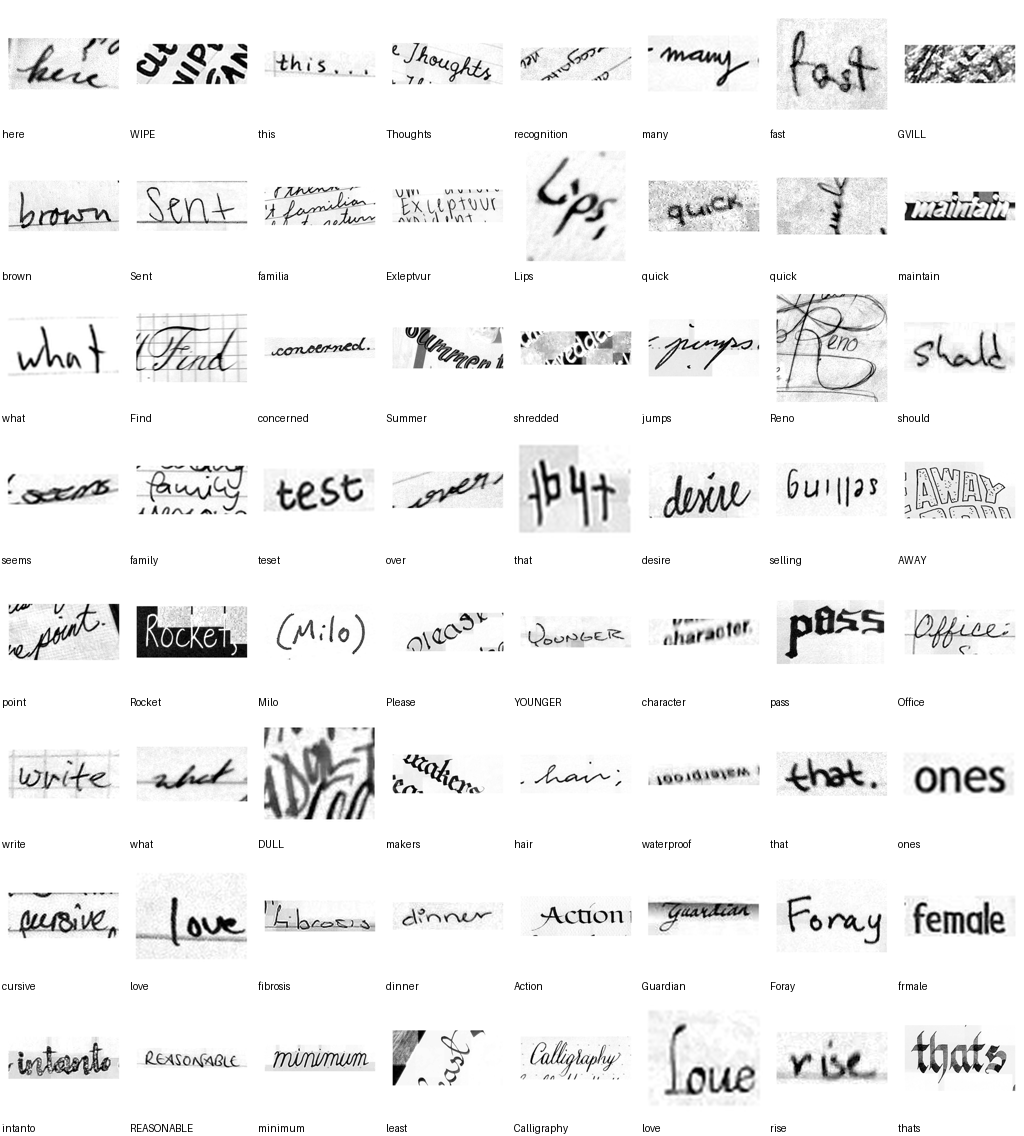

In [13]:
from IPython.display import Image as Show

cmd_preview(NS(images="words/words_256.npy", meta="words/words_meta.csv",
               text_col="word", n=64, out="preview.png"))
Show("preview.png")

### Step 4: OCR
Run the timing test first (1,000 images). It prints images/second and minutes left. Then set `limit=0` to read everything; it saves every 2,000 images and resumes where it stopped.

`workers=0` because functions defined in a notebook cannot be sent to background workers on Windows. Image cleaning then runs in the main process, which costs a few minutes over 50k words.

In [18]:
OCR_SETTINGS = dict(model="microsoft/trocr-base-handwritten", batch_size=32, workers=0,
                    max_new_tokens=16, flush_every=2000, fp32=False)

# words: timing test, then full run (change limit to 0)
cmd_ocr(NS(images="words/words_256.npy", meta="words/words_meta.csv", text_col="word",
           out="words/words_ocr.csv", limit=0, **OCR_SETTINGS))

1000 already done, 49000 to read


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  2016/49000 read, 60.8 img/s, ~13 min left
  4032/49000 read, 52.2 img/s, ~14 min left
  6048/49000 read, 49.4 img/s, ~14 min left
  8064/49000 read, 48.1 img/s, ~14 min left
  10080/49000 read, 47.2 img/s, ~14 min left
  12096/49000 read, 46.6 img/s, ~13 min left
  14112/49000 read, 46.1 img/s, ~13 min left
  16128/49000 read, 45.1 img/s, ~12 min left
  18144/49000 read, 44.2 img/s, ~12 min left
  20160/49000 read, 44.0 img/s, ~11 min left
  22176/49000 read, 43.7 img/s, ~10 min left
  24192/49000 read, 43.3 img/s, ~10 min left
  26208/49000 read, 43.0 img/s, ~9 min left
  28224/49000 read, 42.9 img/s, ~8 min left
  30240/49000 read, 42.8 img/s, ~7 min left
  32256/49000 read, 42.7 img/s, ~7 min left
  34272/49000 read, 42.7 img/s, ~6 min left
  36288/49000 read, 42.7 img/s, ~5 min left
  38304/49000 read, 42.8 img/s, ~4 min left
  40320/49000 read, 42.7 img/s, ~3 min left
  42336/49000 read, 42.7 img/s, ~3 min left
  44352/49000 read, 42.6 img/s, ~2 min left
  46368/49000 read, 42.6

In [19]:
# signatures: relabel with the exact same procedure (1,289 images)
cmd_ocr(NS(images="signature_images_256.npy", meta="splits.csv", text_col="name",
           out="signatures_ocr.csv", limit=0, **OCR_SETTINGS))

1289 already done, 0 to read


### Step 5: labels
Prints the legible rate at several thresholds. Choose the threshold from the words and HF dev only, **before** looking at any holdout result.

In [20]:
THRESHOLD = 0.8

cmd_label(NS(ocr="words/words_ocr.csv", meta="words/words_meta.csv",
             out="words/words_labels.csv", threshold=THRESHOLD))

Saved words/words_labels.csv: 50000 rows, threshold 0.8
Legible rate at other thresholds (decide BEFORE looking at the holdout):
  >= 0.6: 0.621
  >= 0.7: 0.560
  >= 0.8: 0.514
  >= 0.9: 0.441
  >= 1.0: 0.436
        size  legible
split                
test    5000   0.5126
train  40000   0.5160
val     5000   0.5012


In [21]:
cmd_label(NS(ocr="signatures_ocr.csv", meta="splits.csv",
             out="signatures_labels.csv", threshold=THRESHOLD))

Saved signatures_labels.csv: 1289 rows, threshold 0.8
Legible rate at other thresholds (decide BEFORE looking at the holdout):
  >= 0.6: 0.512
  >= 0.7: 0.398
  >= 0.8: 0.296
  >= 0.9: 0.155
  >= 1.0: 0.140
       size   legible
split                
dev    1035  0.292754
test    254  0.311024
Agreement with the earlier labels: 0.941


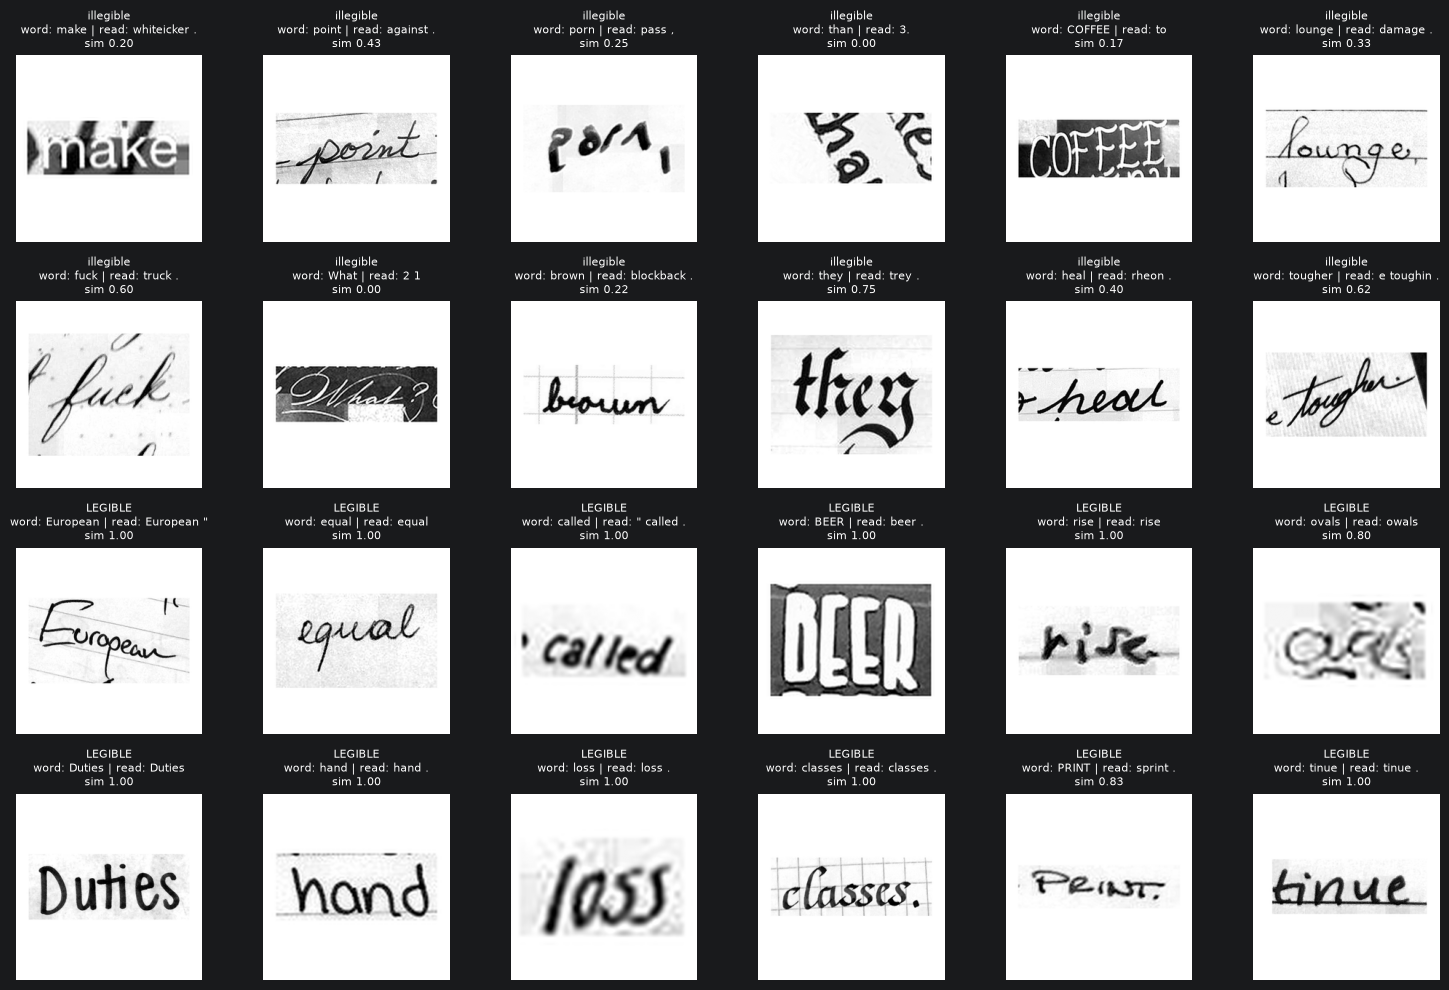

In [23]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
lab = pd.read_csv("words/words_labels.csv")
arr = np.load("words/words_256.npy", mmap_mode="r")

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for k, (row, lbl) in enumerate(zip(axes, [0, 0, 1, 1])):
    sample = lab[lab.label == lbl].sample(6, random_state=k)
    for ax, (_, r) in zip(row, sample.iterrows()):
        ax.imshow(arr[int(r.idx)], cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
        ax.set_title(f"{'LEGIBLE' if lbl else 'illegible'}\nword: {r.target} | read: {r.ocr}\nsim {r.similarity:.2f}",
                     fontsize=8)
plt.tight_layout(); plt.show()

In [24]:
import numpy as np, pandas as pd
lab = pd.read_csv("words/words_labels.csv")
arr = np.load("words/words_256.npy", mmap_mode="r")

lab["n_letters"] = lab["target"].str.replace(r"[^A-Za-z]", "", regex=True).str.len()
# share of dark pixels: normal ink is well under 25%; light-on-dark crops are much higher
lab["dark_frac"] = [(np.asarray(arr[int(i)]) < 128).mean() for i in lab["idx"]]
lab["inverted"] = lab["dark_frac"] > 0.35

print("Light-on-dark crops:", lab["inverted"].mean().round(3), f"({lab['inverted'].sum()} words)")
print("\nLegible rate by word length:")
print(lab.groupby(lab["n_letters"].clip(upper=10))["label"].agg(["size", "mean"]).round(3)
         .rename(columns={"mean": "legible"}).rename(index={10: "10+"}))

Light-on-dark crops: 0.003 (148 words)

Legible rate by word length:
            size  legible
n_letters                
4.0        16238    0.563
5.0        11253    0.560
6.0         7317    0.503
7.0         5871    0.477
8.0         3560    0.447
9.0         2396    0.427
10+         3361    0.347
